In [1]:
import os
import glob
import random
import cv2
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report


In [2]:
path_to_folder = 'data'
IMAGE_SIZE = 32

def get_class_files(root=path_to_folder):
    class_files = {}
    for label in sorted(os.listdir(root)):
        path_dir = os.path.join(root, label)
        if os.path.isdir(path_dir):
            files = glob.glob(os.path.join(path_dir, '*.jpg'))
            if files:
                class_files[label] = files
    return class_files

class_files = get_class_files()
name_folders = list(class_files.keys())
print('Classes:', len(name_folders))
print(name_folders)


Classes: 21
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']


In [3]:
SYMBOL_SPACING = 15
WORD_SPACING = 60

def load_random_symbol(label):
    path = random.choice(class_files[label])
    return cv2.imread(path, cv2.IMREAD_GRAYSCALE)

def generate_sequence(num_words=1, min_len=2, max_len=4, labels=None):
    if labels is None:
        labels = name_folders
    words = []
    images = []
    gaps = []
    for w in range(num_words):
        length = random.randint(min_len, max_len)
        word = [random.choice(labels) for _ in range(length)]
        words.append(word)
        for i, label in enumerate(word):
            images.append(load_random_symbol(label))
            if i < length - 1:
                gaps.append(SYMBOL_SPACING)
        if w < num_words - 1:
            gaps.append(WORD_SPACING)
    text = ' '.join(''.join(label if label != 'times' else '*' for label in word) for word in words)
    return text, images, gaps, words

def compose_sequence(images, gaps, margin=20):
    h = max(img.shape[0] for img in images)
    width = margin * 2 + sum(img.shape[1] for img in images) + sum(gaps)
    canvas = np.full((h + 2 * margin, width), 255, np.uint8)
    x = margin
    for i, img in enumerate(images):
        y = margin + (h - img.shape[0]) // 2
        canvas[y:y + img.shape[0], x:x + img.shape[1]] = img
        x += img.shape[1]
        if i < len(gaps):
            x += gaps[i]
    return canvas

def segment_symbols(image, draw=True):
    if len(image.shape) == 3:
        img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        img_gray = image.copy()
    kernel = np.ones((3, 3), np.uint8)
    img_gray = cv2.erode(img_gray, kernel, iterations=1)
    img_gray = cv2.bitwise_not(img_gray)
    base_size = img_gray.shape[0] + 6, img_gray.shape[1] + 6
    base = np.zeros(base_size, np.uint8)
    base[3:img_gray.shape[0] + 3, 3:img_gray.shape[1] + 3] = img_gray
    base = cv2.cvtColor(base, cv2.COLOR_GRAY2RGB)
    img_rgb = base
    ret, thresh = cv2.threshold(img_rgb, 127, 255, 0)
    contours, h = cv2.findContours(thresh[:, :, 0], cv2.RETR_EXTERNAL, 2)
    crops = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 50:
            if draw:
                cv2.rectangle(img_rgb, (x, y), (x + w, y + h), (0, 0, 255), 2)
            crops.append([x, y, w, h])
    crops = sorted(crops, key=lambda b: b[0])
    data_img = []
    for x, y, w, h in crops:
        x -= 3
        y -= 3
        w += 5
        h += 3
        img = img_gray[y:y + h, x:x + w]
        side = max(img.shape[0], img.shape[1]) + 6
        square = np.zeros((side, side), np.uint8)
        oy = (side - img.shape[0]) // 2
        ox = (side - img.shape[1]) // 2
        square[oy:oy + img.shape[0], ox:ox + img.shape[1]] = img
        data_img.append((x, square))
    return img_rgb, crops, data_img

def crop_to_vector(img):
    base = np.zeros((img.shape[0] + 2, img.shape[1] + 2), np.uint8)
    base[1:img.shape[0] + 1, 1:img.shape[1] + 1] = img
    img = cv2.resize(base, (IMAGE_SIZE, IMAGE_SIZE))
    return np.asarray(img).flatten()

def build_dataset():
    items = [(path, label) for label, files in class_files.items() for path in files]
    random.shuffle(items)
    X = []
    y = []
    used = 0
    i = 0
    while i < len(items):
        length = random.randint(2, 8)
        chunk = items[i:i + length]
        i += length
        if len(chunk) < 2:
            break
        labels = [label for _, label in chunk]
        images = [cv2.imread(path, cv2.IMREAD_GRAYSCALE) for path, _ in chunk]
        if any(img is None for img in images):
            continue
        gaps = [SYMBOL_SPACING] * (len(images) - 1)
        image = compose_sequence(images, gaps)
        _, crops, data_img = segment_symbols(image, draw=False)
        if len(crops) != len(labels):
            continue
        used += len(labels)
        for (_, crop), label in zip(data_img, labels):
            X.append(crop_to_vector(crop))
            y.append(label)
    print('Used images:', used, 'of', len(items))
    return np.asarray(X, dtype=np.uint8), np.asarray(y)

X, y = build_dataset()
print('Images:', X.shape, y.shape)


Used images: 199766 of 225291
Images: (199766, 1024) (199766,)


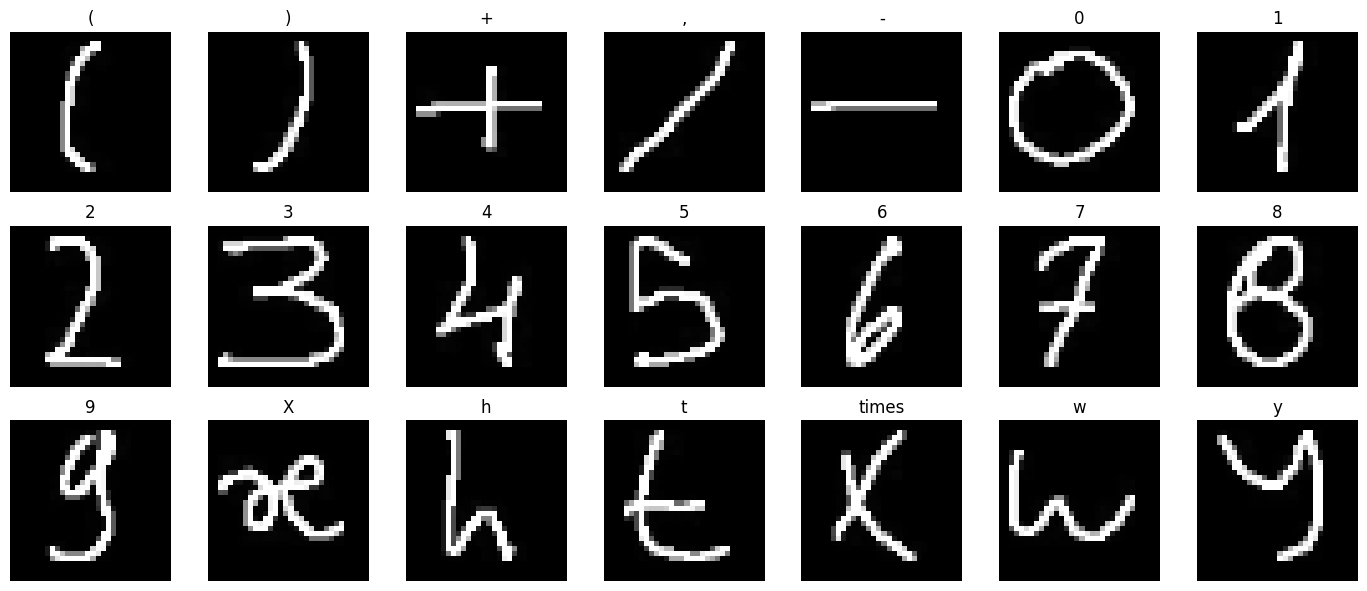

In [4]:
plt.figure(figsize=(14, 6))
for i, label in enumerate(name_folders):
    idx = np.where(y == label)[0][0]
    plt.subplot(3, 7, i + 1)
    plt.imshow(X[idx].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray')
    plt.title(label)
    plt.axis('off')
plt.tight_layout()
plt.show()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
del X
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print('Train:', X_train.shape, 'Test:', X_test.shape)


Train: (159812, 1024) Test: (39954, 1024)


In [6]:
k_values = [1, 3, 5, 7, 9, 11]
sample_size = min(3000, len(X_test))
rng = np.random.default_rng(42)
valid_idx = rng.choice(len(X_test), size=sample_size, replace=False)
X_valid = X_test[valid_idx]
y_valid = y_test[valid_idx]

accuracies = []
for k in k_values:
    classifier = KNeighborsClassifier(n_neighbors=k, algorithm='brute', n_jobs=-1)
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_valid)
    acc = accuracy_score(y_valid, y_pred)
    accuracies.append(acc)
    print('k =', k, 'accuracy =', round(acc, 4))

best_k = k_values[int(np.argmax(accuracies))]
print('Best k:', best_k)


k = 1 accuracy = 0.9947
k = 3 accuracy = 0.9703
k = 5 accuracy = 0.9423
k = 7 accuracy = 0.9347
k = 9 accuracy = 0.9287
k = 11 accuracy = 0.9207
Best k: 1


In [7]:
best_classifier = KNeighborsClassifier(n_neighbors=best_k, algorithm='brute', n_jobs=-1)
best_classifier.fit(X_train, y_train)
y_pred_test = best_classifier.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print('Test accuracy:', round(test_acc, 4))
print(classification_report(y_test, y_pred_test))


Test accuracy: 0.9942
              precision    recall  f1-score   support

           (       0.99      0.99      0.99      2590
           )       1.00      1.00      1.00      2598
           +       1.00      1.00      1.00      4528
           ,       0.82      0.97      0.89       346
           -       1.00      1.00      1.00      6181
           0       1.00      1.00      1.00      1256
           1       0.99      0.99      0.99      4751
           2       1.00      1.00      1.00      4745
           3       0.99      1.00      1.00      1981
           4       1.00      0.99      0.99      1317
           5       1.00      0.99      0.99       568
           6       1.00      0.99      0.99       564
           7       1.00      1.00      1.00       524
           8       1.00      0.99      0.99       545
           9       0.96      0.77      0.85       115
           X       1.00      1.00      1.00      4191
           h       1.00      0.99      0.99       255
     

+X( +*23 -> 7 symbols
5X11 -> 4 symbols
wh h9y -> 5 symbols
+5*h -> 4 symbols
35) -> 3 symbols


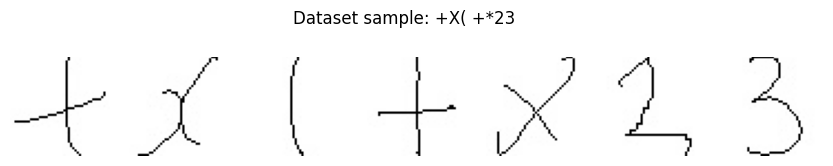

In [8]:
generated = [generate_sequence(num_words=random.randint(1, 2)) for _ in range(5)]
for text, images, gaps, words in generated:
    print(text, '->', len(images), 'symbols')

first_text, first_images, _, _ = generated[0]
plt.figure(figsize=(len(first_images) * 1.5, 2))
for i, img in enumerate(first_images):
    plt.subplot(1, len(first_images), i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle('Dataset sample: ' + first_text)
plt.show()


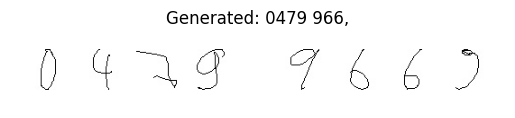

In [12]:
test_text, test_images, test_gaps, test_words = generate_sequence(num_words=2, min_len=2, max_len=4)
test_image = compose_sequence(test_images, test_gaps)
plt.imshow(test_image, cmap='gray')
plt.title('Generated: ' + test_text)
plt.axis('off')
plt.show()


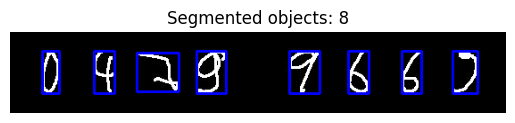

Boxes: [[36, 22, 19, 47], [94, 22, 23, 47], [142, 24, 47, 43], [209, 22, 33, 47], [313, 22, 34, 47], [379, 22, 23, 47], [439, 22, 22, 47], [496, 22, 28, 47]]


In [13]:
img_rgb, crops, data_img = segment_symbols(test_image)
plt.imshow(img_rgb)
plt.title('Segmented objects: ' + str(len(crops)))
plt.axis('off')
plt.show()
print('Boxes:', crops)


In [14]:
def classify_symbols(data_img, model):
    predict_labels = []
    for _, img in data_img:
        predict_labels.append(model.predict(crop_to_vector(img).reshape(1, -1))[0])
    return predict_labels

predict_labels = classify_symbols(data_img, best_classifier)
gaps = [crops[i + 1][0] - (crops[i][0] + crops[i][2]) for i in range(len(crops) - 1)]
s_res = ''
SPACE_GAP = 50
for i, label in enumerate(predict_labels):
    s_res += (label if label != 'times' else '*')
    if i < len(gaps) and gaps[i] > SPACE_GAP:
        s_res += ' '
print('Recognized:', s_res)
print('Ground truth:', test_text)


Recognized: 0429 966,
Ground truth: 0479 966,
